# Quickstart: NOAA RRFS forecasts (sub-hourly, 18 hour, 84 hour), RRFS ENS forecast and REFS forecasts (hourly, 3 hourly), virtual - dynamical.org Icechunk Zarr

NOAA's Rapid Refresh Forecast System family provides convection-allowing forecasts on a 3 km grid covering the contiguous United States. These six datasets offer 15-minute storm evolution, forecasts through 84 hours, six individual members, and REFS ensemble statistics and precipitation probabilities. The deterministic and REFS archives begin in August 2026; RRFS ENS begins on 10 September 2026. All fields shown here are model forecasts.

Dataset documentation:

- RRFS sub-hourly: https://dynamical.org/catalog/noaa-rrfs-forecast-sub-hourly-virtual/
- RRFS 18 hour: https://dynamical.org/catalog/noaa-rrfs-forecast-18-hour-virtual/
- RRFS 84 hour: https://dynamical.org/catalog/noaa-rrfs-forecast-84-hour-virtual/
- RRFS ENS: https://dynamical.org/catalog/noaa-rrfs-ens-forecast-virtual/
- REFS hourly: https://dynamical.org/catalog/noaa-refs-forecast-hourly-virtual/
- REFS 3 hourly: https://dynamical.org/catalog/noaa-refs-forecast-3-hourly-virtual/

The code below opens the public stores anonymously; no AWS credentials are needed. Dataset documentation links will become available when the catalog entries are published.

For local setup, follow the README, then run `uv pip install 'gribberish>=1.8.1'` to install the decoder fixes these stores need.

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install 'icechunk~=2.2.2' 'gribberish>=1.8.1' xarray matplotlib cartopy rioxarray

In [2]:
import icechunk
import xarray as xr


def open_forecast(dataset_id, bucket, *, group=None):
    repository = icechunk.Repository.open(
        icechunk.s3_storage(
            bucket=bucket,
            prefix=f"{dataset_id}/v0.1.0.icechunk",
            region="us-west-2",
            anonymous=True,
        ),
        authorize_virtual_chunk_access=icechunk.containers_credentials({
            "s3://noaa-rrfs-ops-pds/": icechunk.s3_anonymous_credentials(),
        }),
    )
    session = repository.readonly_session("main")
    return xr.open_zarr(
        session.store, group=group, chunks=None,
        consolidated=False, decode_coords="all",
    )


sub_hourly = open_forecast("noaa-rrfs-forecast-sub-hourly-virtual", "dynamical-noaa-rrfs")
rrfs_18h = open_forecast("noaa-rrfs-forecast-18-hour-virtual", "dynamical-noaa-rrfs")
rrfs_84h = open_forecast("noaa-rrfs-forecast-84-hour-virtual", "dynamical-noaa-rrfs")
members = open_forecast("noaa-rrfs-ens-forecast-virtual", "dynamical-noaa-rrfs-ens")
refs_hourly = open_forecast("noaa-refs-forecast-hourly-virtual", "dynamical-noaa-refs")
refs_3hourly = open_forecast("noaa-refs-forecast-3-hourly-virtual", "dynamical-noaa-refs")
rrfs_18h

<xarray.Dataset> Size: 41TB
Dimensions:                                                                                     (
                                                                                                 init_time: 471,
                                                                                                 lead_time: 19,
                                                                                                 y: 1059,
                                                                                                 x: 1799)
Coordinates:
  * init_time                                                                                   (init_time) datetime64[ns] 4kB ...
    expected_forecast_length                                                                    (init_time) timedelta64[us] 4kB ...
  * lead_time                                                                                   (lead_time) timedelta64[us] 152B ...
    valid_time                                                                                  (init_time, lead_time) datetime64[ns] 72kB ...
  * y                                                                                           (y) float64 8kB ...
  * x                                                                                           (x) float64 14kB ...
    latitude                                                                                    (y, x) float32 8MB ...
    longitude                                                                                   (y, x) float32 8MB ...
    spatial_ref                                                                                 int64 8B ...
Data variables: (12/297)
    aerosol_emission_flux_atmosphere_dust_dry_below_10um                                        (init_time, lead_time, y, x) float64 136GB ...
    aerosol_optical_thickness_atmosphere                                                        (init_time, lead_time, y, x) float64 136GB ...
    average_mass_density_8m_total_aerosol_below_10um                                            (init_time, lead_time, y, x) float64 136GB ...
    best_4_layer_lifted_index_180_0mb                                                           (init_time, lead_time, y, x) float64 136GB ...
    brightness_temperature_goes_16_band_11                                                      (init_time, lead_time, y, x) float64 136GB ...
    aerosol_emission_flux_atmosphere_particulate_organic_matter_dry_below_2p5um                 (init_time, lead_time, y, x) float64 136GB ...
    ...                                                                                          ...
    wind_v_max_wind                                                                             (init_time, lead_time, y, x) float64 136GB ...
    wind_v_90_60mb                                                                              (init_time, lead_time, y, x) float64 136GB ...
    wind_v_30m                                                                                  (init_time, lead_time, y, x) float64 136GB ...
    wind_v_planetary_boundary_layer                                                             (init_time, lead_time, y, x) float64 136GB ...
    wind_v_tropopause                                                                           (init_time, lead_time, y, x) float64 136GB ...
    wind_v_60_30mb                                                                              (init_time, lead_time, y, x) float64 136GB ...
Attributes:
    dataset_id:           noaa-rrfs-forecast-18-hour-virtual
    dataset_version:      0.1.0
    name:                 NOAA RRFS forecast, 18 hour, virtual
    description:          Weather forecasts from the Rapid Refresh Forecast S...
    attribution:          NOAA NWS NCEP RRFS data processed by dynamical.org ...
    license:              CC-BY-4.0
    spatial_domain:       Continental United States
    spatial_resolution:   3 km
    time_domai

`init_time` identifies a run and `lead_time` its forecast horizon; `valid_time` combines them. The sub-hourly archive has hourly initializations and 15-minute leads through 18 hours; the 18-hour archive has three-hourly initializations and hourly leads; the 84-hour archive has six-hourly initializations and hourly leads. RRFS ENS and both REFS products initialize every six hours and extend through 60 hours; REFS hourly starts at lead 1 hour and REFS 3 hourly at lead 3 hours.

The shared Lambert Conformal grid uses projected `x` / `y` and 2-D `latitude` / `longitude`. The 18- and 84-hour datasets also have `pressure_level`, `depth_below_ground`, and `height_above_mean_sea_level` groups; RRFS ENS has `pressure_level`. Any vertical group opens with the same helper, for example `open_forecast("noaa-rrfs-forecast-18-hour-virtual", "dynamical-noaa-rrfs", group="pressure_level")`.

## What does a 15-minute step add?

[Thunderstorms crossed the South Plains on the morning of 25 September 2026](https://www.weather.gov/lub/events-2026-20260925-storms). Compare simulated composite reflectivity near Lubbock from the same 06 UTC initialization at 15-minute and hourly lead times, then follow the regional forecast from 12 to 16 UTC. Composite reflectivity is simulated radar reflectivity, not an observed radar mosaic.

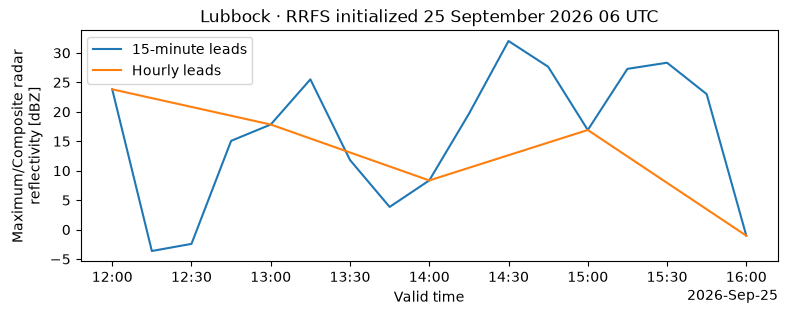

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from pyproj import Transformer
import rioxarray  # enables the .rio accessor

to_xy = Transformer.from_crs("EPSG:4326", rrfs_18h.rio.crs, always_xy=True)
x, y = to_xy.transform(-101.82, 33.58)  # Lubbock, Texas

fig, ax = plt.subplots(figsize=(9, 3))
for ds, label in [(sub_hourly, "15-minute leads"), (rrfs_18h, "Hourly leads")]:
    (
        ds["composite_reflectivity"]
        .sel(init_time="2026-09-25T06", lead_time=slice(np.timedelta64(6, "h"), np.timedelta64(10, "h")))
        .sel(x=x, y=y, method="nearest")
        .plot(ax=ax, x="valid_time", label=label)
    )
ax.set_title("Lubbock · RRFS initialized 25 September 2026 06 UTC")
ax.legend();

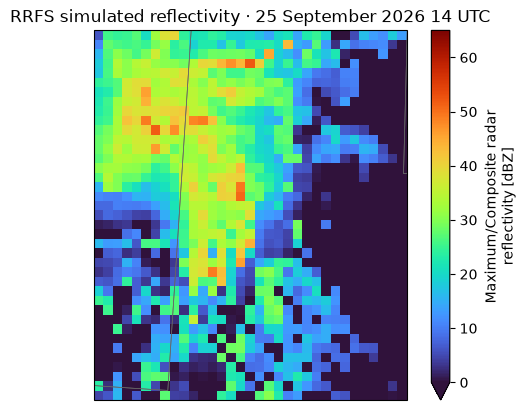

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

crs = rrfs_18h.spatial_ref.attrs
projection = ccrs.LambertConformal(
    central_longitude=crs["longitude_of_central_meridian"],
    central_latitude=crs["latitude_of_projection_origin"],
    standard_parallels=crs["standard_parallel"],
    globe=ccrs.Globe(semimajor_axis=crs["semi_major_axis"], semiminor_axis=crs["semi_minor_axis"]),
)
storms = (
    sub_hourly["composite_reflectivity"]
    .sel(init_time="2026-09-25T06", lead_time=slice(np.timedelta64(6, "h"), np.timedelta64(10, "h")))
    .rio.clip_box(-104, 32, -100, 36, crs="EPSG:4326")
    .isel(x=slice(None, None, 4), y=slice(None, None, 4))
    .load()
)
ax = plt.subplot(projection=projection)
storms.sel(lead_time="8h").plot(
    ax=ax, transform=projection, cmap="turbo", vmin=0, vmax=65, center=False,
)
ax.add_feature(cfeature.STATES, edgecolor="0.4", linewidth=0.5)
ax.set_title("RRFS simulated reflectivity · 25 September 2026 14 UTC");

In [5]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(6, 5), dpi=65, subplot_kw={"projection": projection})
ax.add_feature(cfeature.STATES, edgecolor="0.4", linewidth=0.5)
mesh = storms.isel(lead_time=0).plot(
    ax=ax, transform=projection, cmap="turbo", vmin=0, vmax=65, center=False,
)

def update(i):
    mesh.set_array(storms.isel(lead_time=i).values.ravel())
    ax.set_title("RRFS simulated reflectivity · " + str(storms.valid_time.isel(lead_time=i).values)[:16] + " UTC")

anim = FuncAnimation(fig, update, frames=storms.sizes["lead_time"], interval=250)
plt.close(fig)
HTML(anim.to_jshtml())

## What does the longer forecast show beyond 18 hours?

The [23–27 September 2026 nor'easter](https://www.weather.gov/mhx/SeptemberNoreaster2026) brought several days of strong onshore winds to the Outer Banks. At 00, 06, 12 and 18 UTC, the 18-hour dataset holds the first 18 hours of the same RRFS run that the 84-hour dataset continues, so the curves coincide over their shared first 18 hours. At Cape Hatteras, the run initialized 23 September 00 UTC extends through 26 September 12 UTC in the 84-hour dataset; wind speed is derived from the model's 10 m wind components.

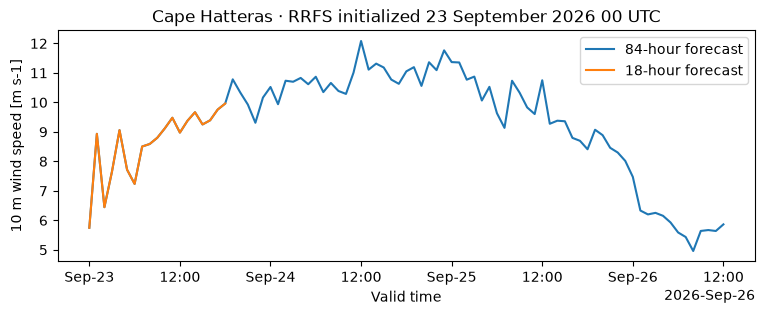

In [6]:
x, y = to_xy.transform(-75.53, 35.22)  # Cape Hatteras, North Carolina
fig, ax = plt.subplots(figsize=(9, 3))
for ds, label in [(rrfs_84h, "84-hour forecast"), (rrfs_18h, "18-hour forecast")]:
    wind = (
        ds[["wind_u_10m", "wind_v_10m"]]
        .sel(init_time="2026-09-23T00", lead_time=slice("0h", "84h"))
        .sel(x=x, y=y, method="nearest")
        .load()
    )
    speed = np.hypot(wind.wind_u_10m, wind.wind_v_10m)
    speed.attrs = {"long_name": "10 m wind speed", "units": "m s-1"}
    speed.plot(ax=ax, x="valid_time", label=label)
ax.set_title("Cape Hatteras · RRFS initialized 23 September 2026 00 UTC")
ax.legend();

## How do individual members and REFS products describe rain?

[Repeated storms caused flooding in northeast Indiana and northwest Ohio on 16–17 September 2026](https://www.weather.gov/iwx/20260916_Flooding). Start with the six RRFS ENS precipitation totals near Bluffton; member 0 is the deterministic forecast. REFS products use a larger, time-lagged member set, so their statistics and probabilities are not a recomputation of these six members from one initialization.

Run-total precipitation is missing at lead zero for these members; the plotted totals begin at lead one hour.

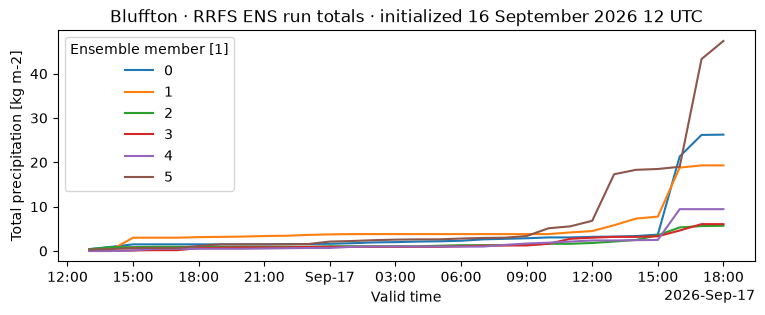

In [7]:
x, y = to_xy.transform(-85.17, 40.74)  # Bluffton, Indiana
rain_members = (
    members["total_precipitation_run_total_surface"]
    .sel(init_time="2026-09-16T12", lead_time=slice("0h", "30h"))
    .sel(x=x, y=y, method="nearest")
    .load()
)
rain_members.plot(x="valid_time", hue="ensemble_member", size=3, aspect=3)
plt.title("Bluffton · RRFS ENS run totals · initialized 16 September 2026 12 UTC");

REFS hourly precipitation stores `mean` and `standard_deviation` along the `statistic` dimension, while each probability threshold is a separate variable without that dimension. The two plots below show NOAA's mean and standard deviation for the preceding hour of precipitation and its neighborhood probability of exceeding 12.7 kg m⁻² (12.7 mm of liquid water) in that hour. Neighborhood probabilities describe nearby exceedances, so they are not pointwise probabilities at the selected grid cell.

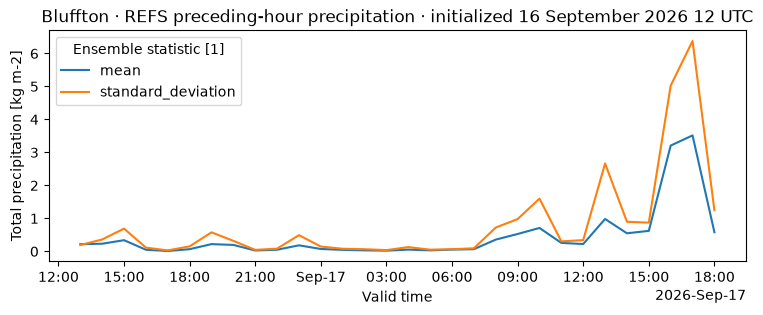

In [8]:
rain_stats = (
    refs_hourly["total_precipitation_1_hour_surface"]
    .sel(init_time="2026-09-16T12", lead_time=slice("1h", "30h"))
    .sel(x=x, y=y, method="nearest")
    .load()
)
rain_stats.plot(x="valid_time", hue="statistic", size=3, aspect=3)
plt.title("Bluffton · REFS preceding-hour precipitation · initialized 16 September 2026 12 UTC");

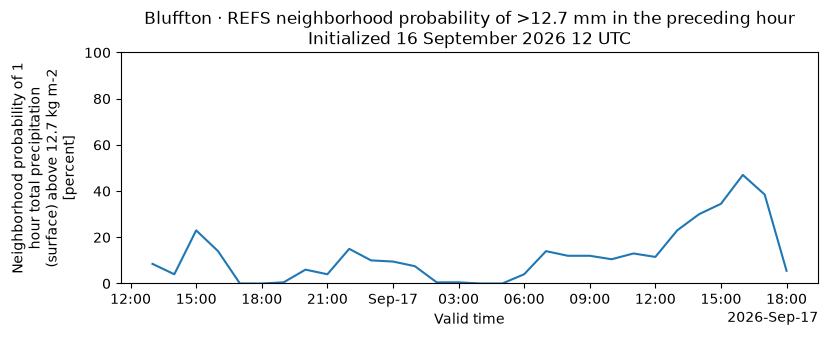

In [9]:
probability = (
    refs_hourly["neighborhood_probability_of_total_precipitation_1_hour_surface_above_12p7"]
    .sel(init_time="2026-09-16T12", lead_time=slice("1h", "30h"))
    .sel(x=x, y=y, method="nearest")
)
probability.plot(x="valid_time", size=3, aspect=3)
plt.ylim(0, 100)
plt.title("Bluffton · REFS neighborhood probability of >12.7 mm in the preceding hour\n"
          "Initialized 16 September 2026 12 UTC");

## Where is heavy rain forecast over a full day?

REFS 3 hourly adds longer accumulation windows evaluated every three forecast hours. For the same Indiana/Ohio event, this map shows the neighborhood probability of more than 25.4 kg m⁻² (25.4 mm) of precipitation in the 24 hours ending 17 September 18 UTC. A 24-hour window first becomes available at lead 24 hours; earlier entries for that field are missing.

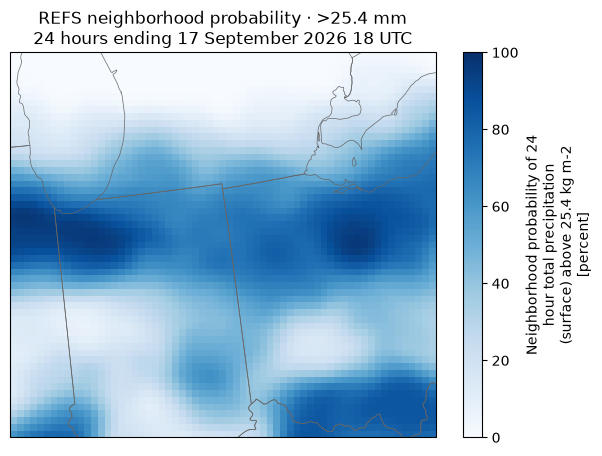

In [10]:
rain_day = (
    refs_3hourly["neighborhood_probability_of_total_precipitation_24_hour_surface_above_25p4"]
    .sel(init_time="2026-09-16T12", lead_time="30h")
    .rio.clip_box(-88, 39, -82, 43, crs="EPSG:4326")
    .isel(x=slice(None, None, 3), y=slice(None, None, 3))
    .load()
)
fig, ax = plt.subplots(figsize=(7, 5), subplot_kw={"projection": projection})
rain_day.plot(ax=ax, transform=projection, cmap="Blues", vmin=0, vmax=100, center=False)
ax.add_feature(cfeature.STATES, edgecolor="0.4", linewidth=0.5)
ax.set_title("REFS neighborhood probability · >25.4 mm\n24 hours ending 17 September 2026 18 UTC");

## Community challenge

- How does storm timing change across successive hourly initializations of the sub-hourly forecast, and does the 15-minute cadence help identify those changes?
- How does a time-lagged collection of RRFS ENS forecasts compare with REFS precipitation probabilities at matching valid times?
- Where does 84-hour wind guidance diverge from later 18-hour runs, and which forecasts verify best against independent observations?